# Deep Learning — Part 3
## Advanced Architectures, Transformers, BERT, ViT and Transfer Learning


### Learning path
1. Connect neural networks, RNN/LSTM/GRU, attention and Transformers
2. Transformer architecture
3. Tokens, embeddings and positional information
4. Self-attention and Transformer blocks
5. Encoder vs decoder
6. BERT and GPT-style models
7. Vision Transformer (ViT)
8. Transfer learning, feature extraction and fine-tuning
9. Model selection, revision notes and self-test

**Big picture:** Transformer is an architecture, BERT/GPT/ViT are model families built using Transformer ideas, and transfer learning is a strategy for reusing a pretrained model.

## 1. Connect the dots: why Transformers?

- **Neural networks** learn patterns by adjusting weights and biases.
- **CNNs** use filters to learn spatial patterns, especially in images.
- **RNNs** process sequences step by step using hidden states.
- **LSTM/GRU** use gates to manage information across sequence steps.
- **Attention** weights information from relevant representations.
- **Self-attention** lets elements in the same sequence use information from other elements.

RNN-family models process sequences recurrently, which can limit parallel processing and make long-range relationships difficult. Self-attention lets positions directly compare with other positions. Transformers build around attention and feed-forward layers without requiring recurrence in their main sequence-processing layers.

**Connection:** RNN → LSTM/GRU improve recurrent memory; attention helps access relevant context; Transformers make attention a central building block.

## 2. What is a Transformer?

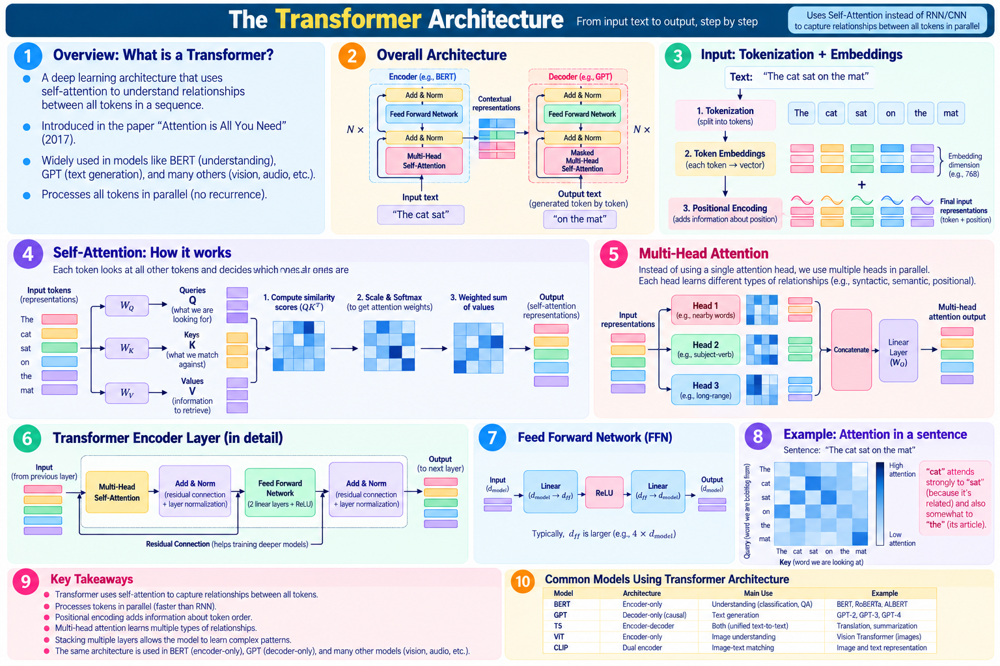

A **Transformer** is a neural-network architecture that uses attention to build context-aware representations of input elements. First introduced for machine translation, it is now used for language, vision, audio and multimodal tasks.

### What, why, when, where
- **What:** Architecture built around attention, feed-forward layers and supporting components.
- **Why:** Models relationships between sequence positions and supports parallel processing during training in many settings.
- **When:** Text understanding, generation, translation, image recognition and multimodal tasks.
- **Where:** BERT, GPT-style models, Vision Transformer (ViT), encoder-decoder translation models.

**Parallel processing nuance:** Transformer encoders can often process input token positions together during training. Autoregressive text generation still produces tokens in order at inference time.

## 3. Tokens, embeddings and positional information

A Transformer does not directly process words as humans understand them. Text is converted into numbers.

1. **Tokenization:** Splits text into tokens. A token may be a word, word piece, punctuation or another unit.
2. **Token IDs:** Each token maps to an integer in a vocabulary.
3. **Embeddings:** Each ID maps to a learned vector of numbers.
4. **Positional information:** Represents token order. Self-attention alone does not inherently encode order, so Transformers need positional embeddings, relative position mechanisms or another way to represent positions.

Example sentence: `Transformers learn context.` A simplified tokenizer might produce `["Transformers", "learn", "context", "."]`; real tokenizers may split it differently.

### Toy example: tokens become vectors
These made-up numbers are for illustration, not real pretrained embeddings.

In [1]:
import numpy as np

toy_embeddings = {
    "Transformers": np.array([0.2, 0.7, 0.1]),
    "learn":        np.array([0.5, 0.1, 0.8]),
    "context":      np.array([0.9, 0.3, 0.4]),
}
for token, vector in toy_embeddings.items():
    print(f"{token:14s} -> {vector}")

Transformers   -> [0.2 0.7 0.1]
learn          -> [0.5 0.1 0.8]
context        -> [0.9 0.3 0.4]


## 4. Self-attention inside a Transformer

For input representations `X`, learned projection matrices produce:
- `Q = X W_Q` — **queries**, representing what each position is looking for
- `K = X W_K` — **keys**, used to calculate relevance scores
- `V = X W_V` — **values**, the information that will be combined

Scaled dot-product attention:

`Attention(Q, K, V) = softmax((Q Kᵀ) / sqrt(d_k)) V`

Steps:
1. Compare queries with keys to calculate scores.
2. Scale the scores by the square root of the key dimension.
3. Apply softmax so each row becomes weights summing to 1.
4. Combine value vectors using those weights.

Each output becomes a context-aware mixture of information from the sequence. This is the same self-attention concept from Part 2; here we see how it fits into a full architecture.

## 5. Encoder, decoder and encoder-decoder

These are common Transformer design patterns.

* **Encoder** : Builds contextual representations of an input. A standard encoder can often attend to tokens on both sides. **BERT** is encoder-based.
* **Decoder**: Generates outputs step by step. An autoregressive decoder uses a **causal mask** to prevent a position from seeing future tokens. **GPT-style models** are commonly decoder-only.
* **Encoder-decoder** The encoder represents the input; the decoder generates an output while attending to the encoder representations. This is useful for machine translation.

Example: French sentence → encoder representations → decoder generates English translation.

## 6. What is inside a Transformer block?

A typical block contains:
1. **Attention:** Mixes information between positions.
2. **Residual connection:** Adds a sublayer's input to its output to support information flow and optimization.
3. **Layer normalization:** Helps stabilize activation scales.
4. **Feed-forward network (FFN):** Transforms features at each position.
5. Residual and normalization operations around sublayers.

Exact ordering differs between designs (for example, pre-norm and post-norm).

**Remember:** Attention mixes information *between positions*; the feed-forward network transforms features *within each position*. Multiple blocks build increasingly contextual representations.

## 7. BERT: language understanding

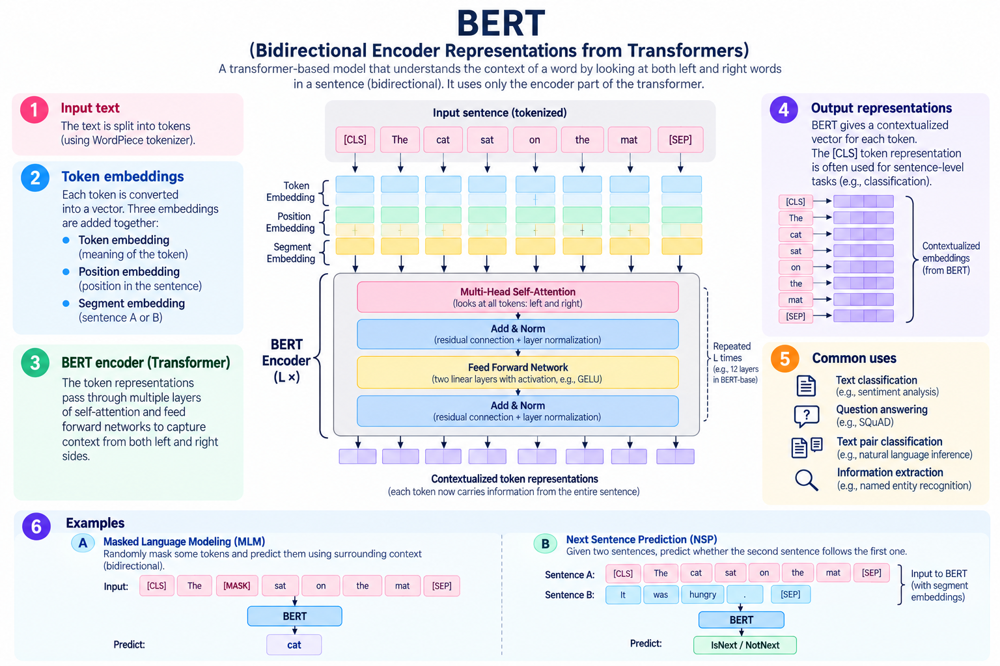

**BERT** means *Bidirectional Encoder Representations from Transformers*. It is an encoder model developed for language understanding. A token representation can use context from both the left and right sides.

Example:
- “I deposited money at the bank.”
- “We sat on the river bank.”

BERT can use surrounding words to form different contextual representations of “bank.”

### Original BERT pretraining
- **Masked Language Modeling (MLM):** Some input tokens are masked or corrupted, and the model learns to predict the original tokens.
- **Next Sentence Prediction (NSP):** The original BERT setup also trained a task predicting whether one segment followed another. Later models use different objectives and may omit NSP.

### Common uses
- Sentiment or text classification
- Named entity recognition
- Extractive question answering
- Sentence/document representations

**Limitation:** Standard BERT is not designed as a left-to-right text generator like GPT. It is primarily an encoder for contextual representations.

### How BERT can be fine-tuned for sentiment
1. Tokenize each review.
2. Feed token IDs and attention masks into BERT.
3. Take an appropriate sequence representation.
4. Add a classification head.
5. Train the head and optionally some or all BERT layers on labeled reviews.

This is also an example of transfer learning.

## 8. GPT-style models: generating text

GPT-style models commonly use a **decoder-only Transformer** trained to predict the next token from previous tokens.

Example prompt: `The weather today is`

The model estimates likely next tokens, selects one according to its generation strategy, appends it, then predicts again. This continues until a stopping condition.

Causal masking prevents the model from using future tokens when learning next-token prediction.

### BERT vs GPT-style
- **BERT:** Encoder, bidirectional context, commonly used for understanding and representations.
- **GPT-style:** Decoder-only, causal context, commonly used for next-token prediction and generation.

These are typical uses, not absolute limits; capabilities depend on training and fine-tuning.

## 9. Vision Transformer (ViT): Transformers for images

A **Vision Transformer (ViT)** applies Transformer-style processing to image patches.

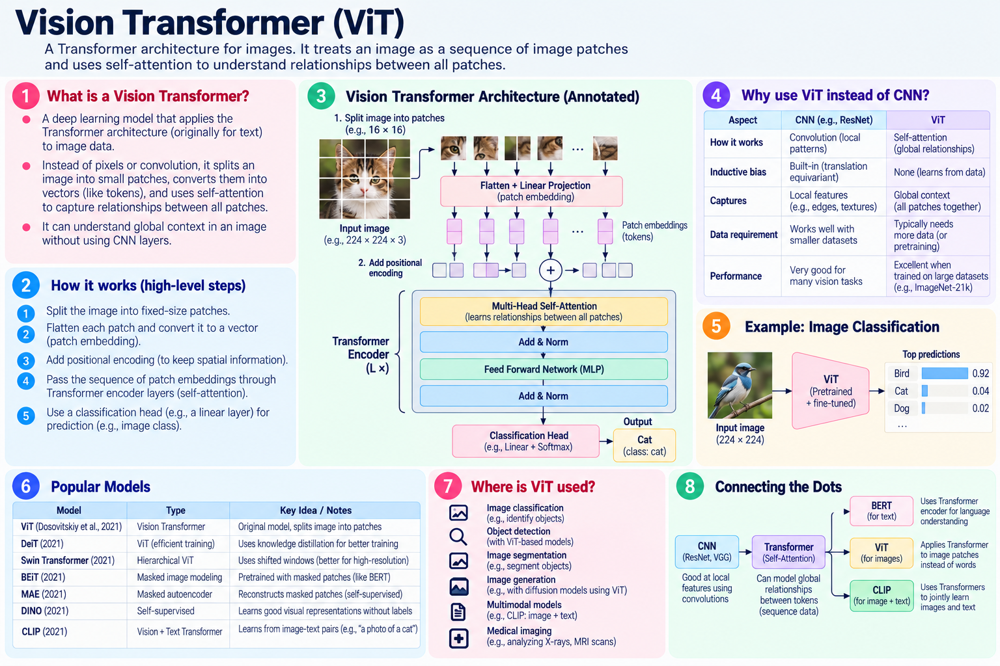

### How it works
1. Split the image into patches, such as 16 × 16 pixels.
2. Flatten and project each patch into an embedding vector.
3. Add positional information to represent patch locations.
4. Process patch embeddings through Transformer encoder blocks.
5. Use a classification representation/head to predict an image class.

Some ViT variants use a special classification token; implementations differ.

### CNN vs ViT
- **CNN:** Uses convolution and shared filters, giving it a strong bias toward local spatial patterns.
- **ViT:** Treats image patches as tokens and uses attention to model relationships between regions.
- **Data:** ViT often benefits from large-scale pretraining. The best choice depends on model, data, compute and task.

ViT does not make CNNs obsolete; both remain useful.

### Calculate patch count
For a 224 × 224 image with non-overlapping 16 × 16 patches, there are 14 patches per side and 196 patches total, excluding any special token.

In [ ]:
image_size = 224
patch_size = 16
patches_per_side = image_size // patch_size
print("Patches per side:", patches_per_side)
print("Total patches:", patches_per_side ** 2)

## 10. Transfer learning: reuse what a model learned

**Transfer learning** reuses knowledge learned on a source task/dataset for a related target task.

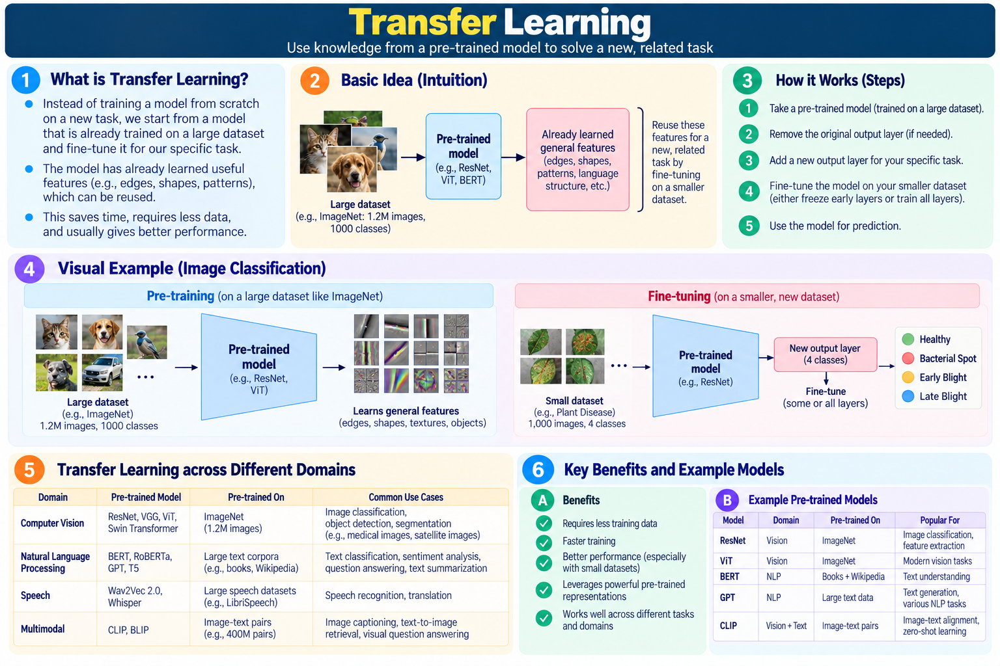

Why useful?
- Training large models from scratch may require lots of data and compute.
- Pretrained models already contain reusable representations.
- A smaller target dataset may be enough to adapt the model.

### Feature extraction
1. Load a pretrained model.
2. Freeze its backbone.
3. Replace/add a task-specific head.
4. Train the new head on your dataset.

Useful when pretrained features are already suitable, especially with limited target data.

### Fine-tuning
1. Start with pretrained weights.
2. Replace the head if needed.
3. Unfreeze some or all backbone layers.
4. Train carefully, often with a smaller learning rate.

Useful when the target task needs the representations to adapt.

### Vocabulary
- **Pretraining:** Initial training on a source task/dataset.
- **Backbone:** Main feature-producing part of the model.
- **Head:** Task-specific output layers.
- **Freeze:** Keep selected parameters unchanged during training.
- **Fine-tuning:** Continue training pretrained parameters for the target task.

## 11. Transfer-learning workflow

**Pretrained model → Replace task head → Freeze or unfreeze layers → Train on target data → Validate → Test**

Examples:
- Pretrained BERT for customer-review sentiment classification.
- Pretrained ViT for plant-disease image classification.
- Pretrained CNN for a small image dataset.

**Avoid data leakage:** Use training data to fit, validation data to select settings, and the test set for final evaluation. Do not repeatedly tune decisions against the test set.

## 12. Practical model-selection guide

| Task | Candidate | Why it may fit |
|---|---|---|
| Sentiment classification with limited labels | TF-IDF + Logistic Regression/SVM; pretrained BERT | Traditional baseline is simple; BERT adds contextual representations |
| Passage-based language understanding | BERT-style encoder | Bidirectional contextual representations |
| Text generation | GPT-style causal Transformer | Predicts next tokens from prior context |
| Translation | Encoder-decoder Transformer | Encoder represents input; decoder generates output |
| Image classification with limited labels | Pretrained CNN or ViT | Reuses visual representations |
| Image task with modest compute | Pretrained CNN can be a practical baseline | Convolutional bias can be efficient |
| Multimodal task | Suitable pretrained multimodal model | May learn aligned representations across modalities |

These are candidate starting points, not universal rules. Compare models fairly with appropriate metrics and data splits.

## 13. Optional PyTorch example: Transformer shapes

This example passes random vectors through a Transformer encoder. It is not a pretrained model and does not learn a language task.

In [ ]:
try:
    import torch
    import torch.nn as nn

    batch_size, sequence_length, embedding_dim, num_heads = 2, 5, 32, 4
    x = torch.randn(batch_size, sequence_length, embedding_dim)

    layer = nn.TransformerEncoderLayer(
        d_model=embedding_dim,
        nhead=num_heads,
        dim_feedforward=64,
        batch_first=True
    )
    encoder = nn.TransformerEncoder(layer, num_layers=2)
    output = encoder(x)

    print("Input shape:", x.shape)
    print("Output shape:", output.shape)
except ImportError:
    print("PyTorch is not installed. Install torch to run this section.")

### Understand the shapes
- Input `(2, 5, 32)`: 2 sequences, 5 positions each, 32 features per position.
- Output `(2, 5, 32)`: same batch and sequence dimensions, with contextualized 32-dimensional features.
- Four attention heads learn different projected relationship patterns.

No causal mask is supplied, so the encoder can attend bidirectionally. Real models also need appropriate tokenization, positional information, training and task-specific masks.

## 14. Common misconceptions

1. **“Transformer is one pretrained model.”** It is an architecture used by many models.
2. **“BERT and GPT are the same.”** BERT is encoder-based and bidirectional; GPT-style models are commonly decoder-only and causal.
3. **“ViT is just a CNN.”** ViT processes patch embeddings with Transformer blocks.
4. **“Transfer learning is an architecture.”** It is a strategy for reusing pretrained knowledge.
5. **“Fine-tuning always trains every layer.”** You can fine-tune selected layers.
6. **“Transformers always need more data than CNNs.”** Data needs depend on architecture, pretraining and task.
7. **“Self-attention knows position automatically.”** Position must be represented through an appropriate mechanism.

## 15. Quick revision sheet

- **Transformer:** Architecture built around attention and feed-forward blocks.
- **Tokenization:** Splitting input text into tokens.
- **Token ID:** Integer representing a vocabulary token.
- **Embedding:** Vector representation of a token or patch.
- **Positional information:** Represents sequence order or image-patch location.
- **Encoder:** Builds input representations.
- **Decoder:** Generates outputs; causal decoders restrict future-token access.
- **BERT:** Bidirectional Transformer encoder, often used for language understanding.
- **MLM:** Predict masked/corrupted tokens during pretraining.
- **GPT-style model:** Commonly decoder-only and trained for next-token prediction.
- **ViT:** Splits an image into patches and processes them with Transformer blocks.
- **Transfer learning:** Reuses knowledge from a pretrained model.
- **Feature extraction:** Freeze backbone and train a task head.
- **Fine-tuning:** Update some or all pretrained parameters for a target task.
- **Backbone:** Main feature-producing layers.
- **Head:** Task-specific output layers.

## 16. Self-test questions

Try to answer without looking at the notes.

1. What problem did Transformers help address compared with recurrent sequence processing?
2. What is a token, and why do we tokenize text?
3. Why does a Transformer need positional information?
4. What is the difference between encoder and decoder?
5. What happens inside a Transformer block?
6. What is BERT, and why is it bidirectional?
7. What is masked language modeling?
8. How does GPT-style text generation work?
9. How does ViT represent an image?
10. State two differences between CNN and ViT.
11. What is transfer learning?
12. Explain feature extraction versus fine-tuning.
13. What is a backbone? What is a head?
14. Why should the test set not be repeatedly used to select models?
15. Choose a candidate for sentiment classification and explain why.

### Suggested study method
1. Review the connection map in Section 1.
2. Understand the Transformer block before memorizing model names.
3. Compare BERT, GPT-style models and ViT.
4. Learn transfer learning after pretrained models make sense.
5. Answer the self-test without notes.